In [1]:
import os
print("Thư mục hiện tại:", os.getcwd())
print("Thư mục cha có gì:", os.listdir(".."))
print()
print("data/processed có gì:")
print(os.listdir("../data/processed") if os.path.exists("../data/processed") else "KHÔNG TỒN TẠI")

Thư mục hiện tại: C:\Users\tiend\projects\bank-marketing-prediction\notebooks
Thư mục cha có gì: ['.git', '.gitignore', '.ipynb_checkpoints', '02_decision_tree_rf.ipynb', 'data', 'models', 'notebooks', 'README.md', 'reports', 'requirements.txt', 'src']

data/processed có gì:
['data_dictionary.md', 'test.parquet', 'test_raw.parquet', 'test_time.parquet', 'test_with_duration.parquet', 'train.parquet', 'train_raw.parquet', 'train_time.parquet', 'train_with_duration.parquet']


In [2]:
import os
print("Đang đứng ở:", os.getcwd())
print()

# tìm thư mục gốc repo (nơi có thư mục src), thử ở thư mục hiện tại và thư mục cha
for base in [".", ".."]:
    print(f"--- Nội dung của '{base}' ---")
    print(os.listdir(base))
    print()

# tìm mọi file .parquet trong vùng lân cận
print("--- Các file .parquet tìm được ---")
found = False
for root in [".", ".."]:
    for dirpath, dirs, files in os.walk(root):
        for f in files:
            if f.endswith(".parquet"):
                print(os.path.join(dirpath, f)); found = True
if not found:
    print("KHÔNG CÓ file .parquet nào")

Đang đứng ở: C:\Users\tiend\projects\bank-marketing-prediction\notebooks

--- Nội dung của '.' ---
['.ipynb_checkpoints', '01_eda_preprocessing.ipynb', '02_decision_tree_rf.ipynb', '03_spark_mllib.ipynb', '04_experiments_comparison.ipynb']

--- Nội dung của '..' ---
['.git', '.gitignore', '.ipynb_checkpoints', '02_decision_tree_rf.ipynb', 'data', 'models', 'notebooks', 'README.md', 'reports', 'requirements.txt', 'src']

--- Các file .parquet tìm được ---
..\data\processed\test.parquet
..\data\processed\test_raw.parquet
..\data\processed\test_time.parquet
..\data\processed\test_with_duration.parquet
..\data\processed\train.parquet
..\data\processed\train_raw.parquet
..\data\processed\train_time.parquet
..\data\processed\train_with_duration.parquet


In [3]:
import sys
import pandas as pd
sys.path.append("..")
from src.metrics import evaluate

train_df = pd.read_parquet("../data/processed/train.parquet")
print(train_df.shape)    # kỳ vọng (32940, 65)

(32940, 65)


In [4]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from src.metrics import evaluate

RANDOM_STATE = 42

train_df = pd.read_parquet("../data/processed/train.parquet")
test_df  = pd.read_parquet("../data/processed/test.parquet")

X_train, y_train = train_df.drop(columns=["y"]), train_df["y"]
X_test,  y_test  = test_df.drop(columns=["y"]),  test_df["y"]

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))

(32940, 64) (8236, 64)
y
0    0.887341
1    0.112659
Name: proportion, dtype: float64


=== KẾT QUẢ ĐÁNH GIÁ: Decision Tree (baseline) (Threshold = 0.5) ===
Precision : 0.3080
Recall    : 0.3491
F1-Score  : 0.3273
ROC-AUC   : 0.6254
PR-AUC    : 0.1825

Chi tiết từng lớp:
              precision    recall  f1-score   support

      No (0)     0.9159    0.9004    0.9081      7308
     Yes (1)     0.3080    0.3491    0.3273       928

    accuracy                         0.8383      8236
   macro avg     0.6120    0.6248    0.6177      8236
weighted avg     0.8474    0.8383    0.8426      8236



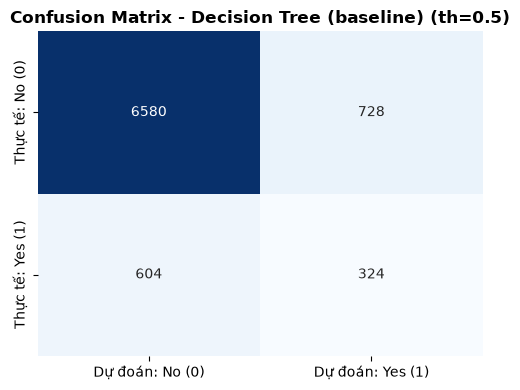

In [5]:
from sklearn.tree import DecisionTreeClassifier

results = []   # danh sách gom kết quả để làm bảng so sánh sau này

dt_base = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_base.fit(X_train, y_train)

prob = dt_base.predict_proba(X_test)[:, 1]
results.append(evaluate(y_test, y_prob=prob, model_name="Decision Tree (baseline)"))

=== KẾT QUẢ ĐÁNH GIÁ: Random Forest (baseline) (Threshold = 0.5) ===
Precision : 0.5436
Recall    : 0.2888
F1-Score  : 0.3772
ROC-AUC   : 0.7772
PR-AUC    : 0.4260

Chi tiết từng lớp:
              precision    recall  f1-score   support

      No (0)     0.9148    0.9692    0.9412      7308
     Yes (1)     0.5436    0.2888    0.3772       928

    accuracy                         0.8925      8236
   macro avg     0.7292    0.6290    0.6592      8236
weighted avg     0.8729    0.8925    0.8777      8236



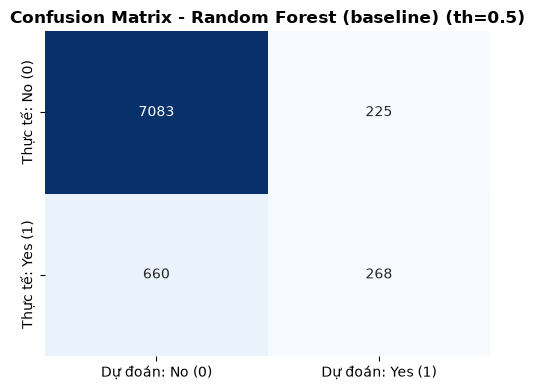

In [6]:
from sklearn.ensemble import RandomForestClassifier

rf_base = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
rf_base.fit(X_train, y_train)

prob = rf_base.predict_proba(X_test)[:, 1]
results.append(evaluate(y_test, y_prob=prob, model_name="Random Forest (baseline)"))

In [7]:
pd.DataFrame(results)

,Model,Threshold,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Decision Tree (baseline),0.5,0.3080,0.3491,0.3273,0.6254,0.1825,6580,728,604,324
1,Random Forest (baseline),0.5,0.5436,0.2888,0.3772,0.7772,0.4260,7083,225,660,268


In [8]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

dt_params = {
    "max_depth": [3, 4, 5, 6, 8, 10, 15],
    "min_samples_leaf": [1, 5, 10, 20, 50, 100],
    "class_weight": [None, "balanced"],
}

dt_search = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_distributions=dt_params,
    n_iter=30,
    scoring="average_precision",
    cv=cv, n_jobs=-1, random_state=RANDOM_STATE, verbose=1,
)
dt_search.fit(X_train, y_train)

print("Tham số tốt nhất:", dt_search.best_params_)
print("PR-AUC trung bình (CV):", round(dt_search.best_score_, 4))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Tham số tốt nhất: {'min_samples_leaf': 100, 'max_depth': 10, 'class_weight': None}
PR-AUC trung bình (CV): 0.4359


In [9]:
rf_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [6, 8, 12, 16, None],
    "min_samples_leaf": [1, 5, 10, 20],
    "max_features": ["sqrt", 0.5],
    "class_weight": [None, "balanced", "balanced_subsample"],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=rf_params,
    n_iter=20,
    scoring="average_precision",
    cv=cv, n_jobs=1, random_state=RANDOM_STATE, verbose=1,
)
rf_search.fit(X_train, y_train)

print("Tham số tốt nhất:", rf_search.best_params_)
print("PR-AUC trung bình (CV):", round(rf_search.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Tham số tốt nhất: {'n_estimators': 300, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 12, 'class_weight': None}
PR-AUC trung bình (CV): 0.4692


=== KẾT QUẢ ĐÁNH GIÁ: Decision Tree (tuned) (Threshold = 0.5) ===
Precision : 0.6687
Recall    : 0.2349
F1-Score  : 0.3477
ROC-AUC   : 0.8030
PR-AUC    : 0.4686

Chi tiết từng lớp:
              precision    recall  f1-score   support

      No (0)     0.9102    0.9852    0.9462      7308
     Yes (1)     0.6687    0.2349    0.3477       928

    accuracy                         0.9007      8236
   macro avg     0.7895    0.6101    0.6470      8236
weighted avg     0.8830    0.9007    0.8788      8236



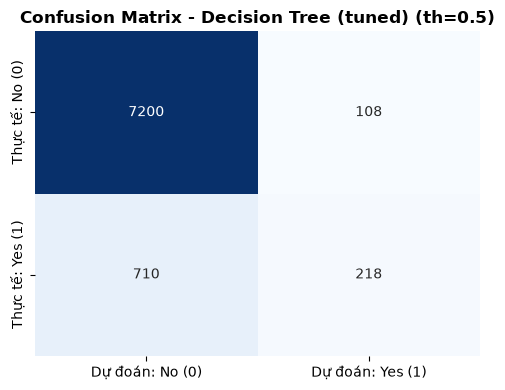

=== KẾT QUẢ ĐÁNH GIÁ: Random Forest (tuned) (Threshold = 0.5) ===
Precision : 0.6746
Recall    : 0.2435
F1-Score  : 0.3579
ROC-AUC   : 0.8121
PR-AUC    : 0.4876

Chi tiết từng lớp:
              precision    recall  f1-score   support

      No (0)     0.9112    0.9851    0.9467      7308
     Yes (1)     0.6746    0.2435    0.3579       928

    accuracy                         0.9015      8236
   macro avg     0.7929    0.6143    0.6523      8236
weighted avg     0.8845    0.9015    0.8803      8236



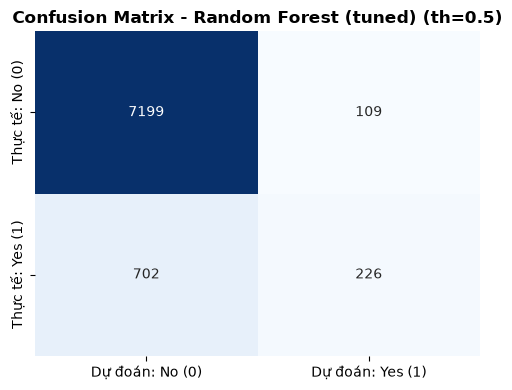

,Model,Threshold,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Decision Tree (baseline),0.5,0.3080,0.3491,0.3273,0.6254,0.1825,6580,728,604,324
1,Random Forest (baseline),0.5,0.5436,0.2888,0.3772,0.7772,0.4260,7083,225,660,268
2,Decision Tree (tuned),0.5,0.6687,0.2349,0.3477,0.8030,0.4686,7200,108,710,218
3,Random Forest (tuned),0.5,0.6746,0.2435,0.3579,0.8121,0.4876,7199,109,702,226


In [10]:
dt_best = dt_search.best_estimator_
rf_best = rf_search.best_estimator_

results.append(evaluate(y_test, y_prob=dt_best.predict_proba(X_test)[:, 1],
                        model_name="Decision Tree (tuned)"))
results.append(evaluate(y_test, y_prob=rf_best.predict_proba(X_test)[:, 1],
                        model_name="Random Forest (tuned)"))

pd.DataFrame(results)

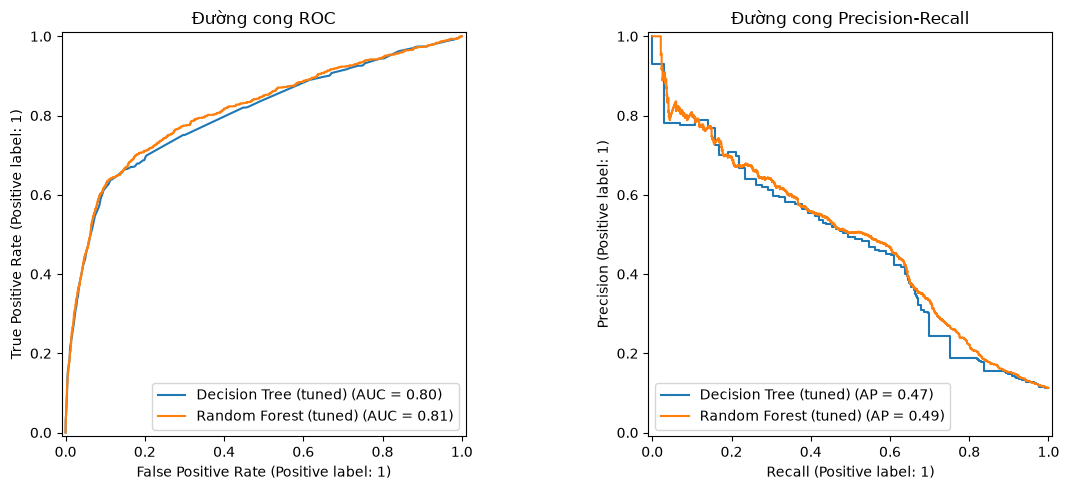

In [11]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for name, model in [("Decision Tree (tuned)", dt_best), ("Random Forest (tuned)", rf_best)]:
    prob = model.predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=name, ax=ax[1])

ax[0].set_title("Đường cong ROC")
ax[1].set_title("Đường cong Precision-Recall")
plt.tight_layout()
plt.savefig("../reports/figures/tv2_roc_pr.png", dpi=150)
plt.show()

In [12]:
joblib.dump(dt_best, "../models/tv2_decision_tree.joblib")
joblib.dump(rf_best, "../models/tv2_random_forest.joblib")

['../models/tv2_random_forest.joblib']

In [13]:
COST_PER_CALL = 5       # chi phí mỗi cuộc gọi (giả định)
REVENUE_PER_SIGNUP = 50 # doanh thu mỗi khách đăng ký (giả định)

def profit(signups, calls):
    return signups * REVENUE_PER_SIGNUP - calls * COST_PER_CALL

print("Ngưỡng hòa vốn lý thuyết:", COST_PER_CALL / REVENUE_PER_SIGNUP)

Ngưỡng hòa vốn lý thuyết: 0.1


In [14]:
from sklearn.model_selection import cross_val_predict

oof_prob = cross_val_predict(
    rf_best, X_train, y_train,
    cv=cv, method="predict_proba", n_jobs=1,
)[:, 1]

print(oof_prob.shape)          # kỳ vọng (32940,)
print(oof_prob.min(), oof_prob.max())

(32940,)
0.014699802371308055 0.8986210896934352


Ngưỡng tối ưu: 0.1
Lợi nhuận tại ngưỡng đó: 85255.0
Lợi nhuận nếu gọi tất cả: 20850


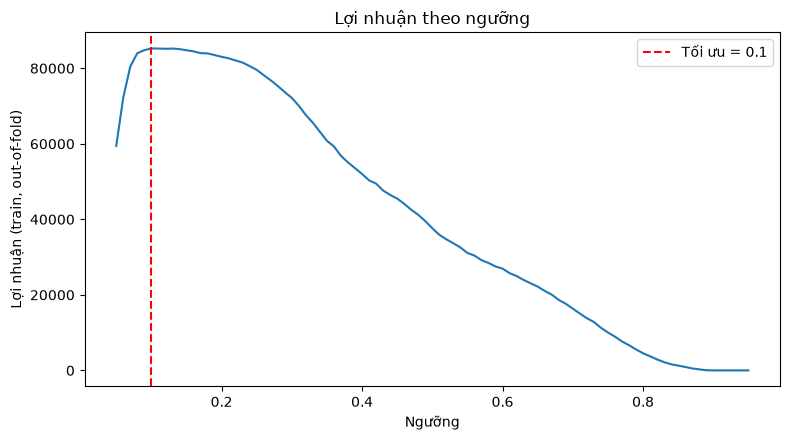

In [15]:
thresholds = np.arange(0.05, 0.96, 0.01)
y_arr = y_train.to_numpy()

rows = []
for t in thresholds:
    called = oof_prob >= t                 # khách bị gọi ở ngưỡng t
    calls = int(called.sum())
    signups = int((called & (y_arr == 1)).sum())
    rows.append({
        "threshold": round(float(t), 2),
        "calls": calls,
        "signups": signups,
        "precision": signups / calls if calls else 0.0,
        "profit": profit(signups, calls),
    })
sweep = pd.DataFrame(rows)

best = sweep.loc[sweep["profit"].idxmax()]
call_all = profit(int(y_arr.sum()), len(y_arr))   # đối chứng: gọi tất cả

print("Ngưỡng tối ưu:", best["threshold"])
print("Lợi nhuận tại ngưỡng đó:", best["profit"])
print("Lợi nhuận nếu gọi tất cả:", call_all)

plt.figure(figsize=(8, 4.5))
plt.plot(sweep["threshold"], sweep["profit"])
plt.axvline(best["threshold"], color="red", linestyle="--",
            label=f"Tối ưu = {best['threshold']}")
plt.xlabel("Ngưỡng"); plt.ylabel("Lợi nhuận (train, out-of-fold)")
plt.title("Lợi nhuận theo ngưỡng"); plt.legend()
plt.tight_layout()
plt.savefig("../reports/figures/tv2_profit_threshold.png", dpi=150)
plt.show()

=== KẾT QUẢ ĐÁNH GIÁ: Random Forest (tuned) - ngưỡng 0.1 (Threshold = 0.1) ===
Precision : 0.3528
Recall    : 0.6713
F1-Score  : 0.4625
ROC-AUC   : 0.8121
PR-AUC    : 0.4876

Chi tiết từng lớp:
              precision    recall  f1-score   support

      No (0)     0.9529    0.8436    0.8949      7308
     Yes (1)     0.3528    0.6713    0.4625       928

    accuracy                         0.8242      8236
   macro avg     0.6528    0.7575    0.6787      8236
weighted avg     0.8852    0.8242    0.8462      8236



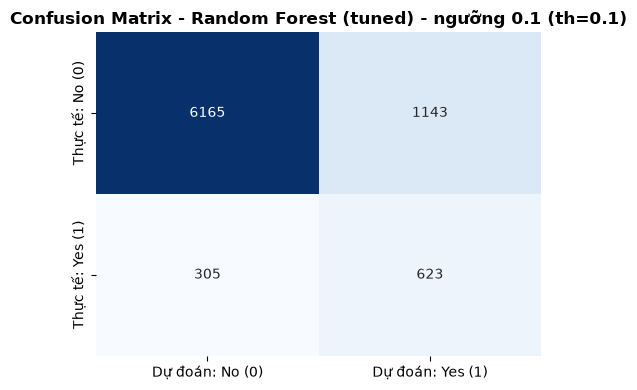

Số cuộc gọi: 1766 | Khách chốt: 623 | Lợi nhuận trên test: 22320


In [16]:
import json

BEST_T = float(best["threshold"])
prob_test = rf_best.predict_proba(X_test)[:, 1]
y_t = y_test.to_numpy()

res_best = evaluate(y_test, y_prob=prob_test, threshold=BEST_T,
                    model_name=f"Random Forest (tuned) - ngưỡng {BEST_T}")

called = prob_test >= BEST_T
calls = int(called.sum())
signups = int((called & (y_t == 1)).sum())
print("Số cuộc gọi:", calls, "| Khách chốt:", signups,
      "| Lợi nhuận trên test:", profit(signups, calls))

with open("../models/threshold.json", "w") as f:
    json.dump({"threshold": BEST_T,
               "cost_per_call": COST_PER_CALL,
               "revenue_per_signup": REVENUE_PER_SIGNUP}, f, indent=2)

In [17]:
scen = []
for t in sorted(set([0.05, 0.10, 0.15, 0.20, 0.30, 0.50, BEST_T])):
    called = prob_test >= t
    calls = int(called.sum())
    signups = int((called & (y_t == 1)).sum())
    scen.append({
        "Kịch bản": f"Ngưỡng {t}",
        "Số cuộc gọi": calls,
        "Khách chốt": signups,
        "Tỷ lệ chốt": round(signups / calls, 4) if calls else 0,
        "Recall": round(signups / y_t.sum(), 4),
        "Lợi nhuận": profit(signups, calls),
    })

scen.append({
    "Kịch bản": "Gọi tất cả",
    "Số cuộc gọi": len(y_t),
    "Khách chốt": int(y_t.sum()),
    "Tỷ lệ chốt": round(y_t.mean(), 4),
    "Recall": 1.0,
    "Lợi nhuận": profit(int(y_t.sum()), len(y_t)),
})

scen_df = pd.DataFrame(scen)
scen_df

,Kịch bản,Số cuộc gọi,Khách chốt,Tỷ lệ chốt,Recall,Lợi nhuận
0,Ngưỡng 0.05,5206,822,0.1579,0.8858,15070
1,Ngưỡng 0.1,1766,623,0.3528,0.6713,22320
2,Ngưỡng 0.15,1364,589,0.4318,0.6347,22630
3,Ngưỡng 0.2,1221,561,0.4595,0.6045,21945
4,Ngưỡng 0.3,915,460,0.5027,0.4957,18425
5,Ngưỡng 0.5,335,226,0.6746,0.2435,9625
6,Gọi tất cả,8236,928,0.1127,1.0000,5220


In [18]:
thr_s = np.arange(0.01, 0.96, 0.01)
sens = []
for rev in [20, 50, 100, 200]:
    best_t, best_p = None, -np.inf
    for t in thr_s:
        called = oof_prob >= t
        calls = int(called.sum())
        s = int((called & (y_arr == 1)).sum())
        p_ = s * rev - calls * COST_PER_CALL
        if p_ > best_p:
            best_t, best_p = round(float(t), 2), p_
    sens.append({"Doanh thu/khách": rev, "Chi phí/cuộc gọi": COST_PER_CALL,
                 "Hòa vốn lý thuyết": round(COST_PER_CALL / rev, 3),
                 "Ngưỡng tối ưu": best_t, "Lợi nhuận (train)": best_p})
pd.DataFrame(sens)

,Doanh thu/khách,Chi phí/cuộc gọi,Hòa vốn lý thuyết,Ngưỡng tối ưu,Lợi nhuận (train)
0,20,5,0.250,0.23,18625
1,50,5,0.100,0.10,85255
2,100,5,0.050,0.05,223175
3,200,5,0.025,0.01,577500


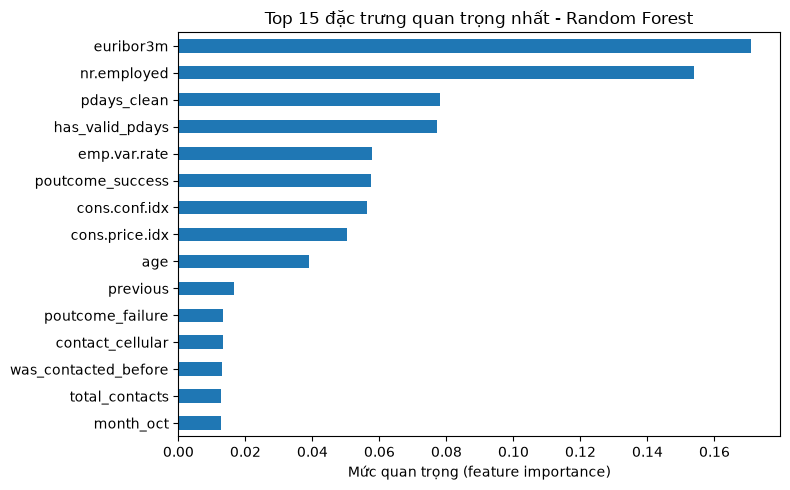

euribor3m               0.171006
nr.employed             0.153940
pdays_clean             0.078171
has_valid_pdays         0.077178
emp.var.rate            0.057860
poutcome_success        0.057341
cons.conf.idx           0.056166
cons.price.idx          0.050465
age                     0.039119
previous                0.016721
poutcome_failure        0.013395
contact_cellular        0.013164
was_contacted_before    0.012939
total_contacts          0.012856
month_oct               0.012628
dtype: float64

In [19]:
imp = pd.Series(rf_best.feature_importances_, index=X_train.columns).sort_values(ascending=False)
top = imp.head(15)

plt.figure(figsize=(8, 5))
top[::-1].plot(kind="barh")
plt.xlabel("Mức quan trọng (feature importance)")
plt.title("Top 15 đặc trưng quan trọng nhất - Random Forest")
plt.tight_layout()
plt.savefig("../reports/figures/tv2_feature_importance.png", dpi=150)
plt.show()

top

=== KẾT QUẢ ĐÁNH GIÁ: RF tuned - chia theo thời gian (ngưỡng 0.1) (Threshold = 0.1) ===
Precision : 0.4330
Recall    : 0.8590
F1-Score  : 0.5758
ROC-AUC   : 0.7481
PR-AUC    : 0.5459

Chi tiết từng lớp:
              precision    recall  f1-score   support

      No (0)     0.8881    0.4987    0.6387      5697
     Yes (1)     0.4330    0.8590    0.5758      2539

    accuracy                         0.6098      8236
   macro avg     0.6605    0.6788    0.6072      8236
weighted avg     0.7478    0.6098    0.6193      8236



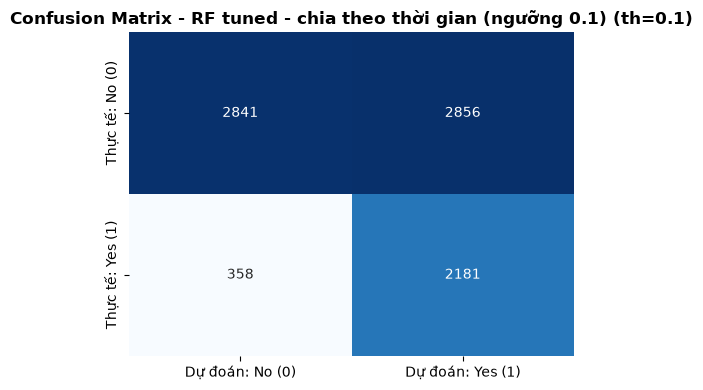

Số cuộc gọi: 5037 | Khách chốt: 2181 | Lợi nhuận: 83865
Lợi nhuận nếu gọi tất cả: 85770


In [20]:
from sklearn.base import clone

train_t = pd.read_parquet("../data/processed/train_time.parquet")
test_t  = pd.read_parquet("../data/processed/test_time.parquet")
Xtr_t, ytr_t = train_t.drop(columns=["y"]), train_t["y"]
Xte_t, yte_t = test_t.drop(columns=["y"]),  test_t["y"]

rf_time = clone(rf_best).fit(Xtr_t, ytr_t)       # cùng tham số, huấn luyện lại trên dữ liệu cũ
prob_time = rf_time.predict_proba(Xte_t)[:, 1]

evaluate(yte_t, y_prob=prob_time, threshold=BEST_T,
         model_name="RF tuned - chia theo thời gian (ngưỡng 0.1)")

yt = yte_t.to_numpy()
called = prob_time >= BEST_T
calls, signups = int(called.sum()), int((called & (yt == 1)).sum())
print("Số cuộc gọi:", calls, "| Khách chốt:", signups, "| Lợi nhuận:", profit(signups, calls))
print("Lợi nhuận nếu gọi tất cả:", profit(int(yt.sum()), len(yt)))

In [21]:
print("Tỷ lệ yes - train_time:", round(ytr_t.mean(), 4), "| test_time:", round(yte_t.mean(), 4))
print("Tỷ lệ yes - train (ngẫu nhiên):", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

Tỷ lệ yes - train_time: 0.0638 | test_time: 0.3083
Tỷ lệ yes - train (ngẫu nhiên): 0.1127 | test: 0.1127


In [22]:
oof_t = cross_val_predict(clone(rf_best), Xtr_t, ytr_t, cv=cv,
                          method="predict_proba", n_jobs=1)[:, 1]
ytr_arr = ytr_t.to_numpy()

best_t_time, best_p = None, -np.inf
for t in np.arange(0.05, 0.96, 0.01):
    called = oof_t >= t
    calls = int(called.sum())
    s = int((called & (ytr_arr == 1)).sum())
    if profit(s, calls) > best_p:
        best_t_time, best_p = round(float(t), 2), profit(s, calls)
print("Ngưỡng tối ưu chọn từ train_time:", best_t_time)

called = prob_time >= best_t_time
calls, signups = int(called.sum()), int((called & (yt == 1)).sum())
print("Trên test_time -> cuộc gọi:", calls, "| chốt:", signups, "| lợi nhuận:", profit(signups, calls))

Ngưỡng tối ưu chọn từ train_time: 0.13
Trên test_time -> cuộc gọi: 4255 | chốt: 1959 | lợi nhuận: 76675


In [23]:
from sklearn.metrics import roc_auc_score, average_precision_score

macro_cols = ["euribor3m", "nr.employed", "emp.var.rate", "cons.conf.idx", "cons.price.idx"]
splits = {
    "Chia ngẫu nhiên": (X_train, y_train, X_test, y_test),
    "Chia theo thời gian": (Xtr_t, ytr_t, Xte_t, yte_t),
}

rows = []
for split_name, (Xa, ya, Xb, yb) in splits.items():
    for label, drop in [("Đủ biến", []), ("Bỏ 5 biến vĩ mô", macro_cols)]:
        m = clone(rf_best).fit(Xa.drop(columns=drop), ya)
        p = m.predict_proba(Xb.drop(columns=drop))[:, 1]
        rows.append({"Cách chia": split_name, "Bộ biến": label,
                     "ROC-AUC": round(roc_auc_score(yb, p), 4),
                     "PR-AUC": round(average_precision_score(yb, p), 4)})
pd.DataFrame(rows)

,Cách chia,Bộ biến,ROC-AUC,PR-AUC
0,Chia ngẫu nhiên,Đủ biến,0.8121,0.4876
1,Chia ngẫu nhiên,Bỏ 5 biến vĩ mô,0.7811,0.4278
2,Chia theo thời gian,Đủ biến,0.7481,0.5459
3,Chia theo thời gian,Bỏ 5 biến vĩ mô,0.6925,0.4841


In [24]:
tmp = X_train.copy()
tmp["y"] = y_train

print("Tỷ lệ yes theo poutcome_success:")
print(tmp.groupby("poutcome_success")["y"].mean().round(3))

print("\nTỷ lệ yes theo 4 nhóm euribor3m (thấp đến cao):")
print(tmp.groupby(pd.qcut(tmp["euribor3m"], 4, duplicates="drop"), observed=True)["y"].mean().round(3))

Tỷ lệ yes theo poutcome_success:
poutcome_success
0.0    0.094
1.0    0.660
Name: y, dtype: float64

Tỷ lệ yes theo 4 nhóm euribor3m (thấp đến cao):
euribor3m
(0.633, 1.344]    0.251
(1.344, 4.857]    0.083
(4.857, 4.961]    0.051
(4.961, 5.045]    0.057
Name: y, dtype: float64


In [25]:
print("euribor3m trung bình - train_time:", round(Xtr_t["euribor3m"].mean(), 3),
      "| test_time:", round(Xte_t["euribor3m"].mean(), 3))

euribor3m trung bình - train_time: 4.269 | test_time: 1.031


In [26]:
lo, hi = Xtr_t["euribor3m"].min(), Xtr_t["euribor3m"].max()
print("euribor3m trong train_time:", round(lo, 3), "->", round(hi, 3))
print("euribor3m trong test_time :", round(Xte_t["euribor3m"].min(), 3), "->", round(Xte_t["euribor3m"].max(), 3))
print("Tỷ lệ dòng test_time có euribor3m thấp hơn mức thấp nhất của train_time:",
      round((Xte_t["euribor3m"] < lo).mean(), 3))

euribor3m trong train_time: 1.299 -> 5.045
euribor3m trong test_time : 0.634 -> 1.299
Tỷ lệ dòng test_time có euribor3m thấp hơn mức thấp nhất của train_time: 0.985
